# xGoal Model Training

## Import Libraries

In [1]:
import os

# Print current working directory
print(os.getcwd())

# Change to your desired directory
os.chdir('/Users/svasquez/driblab/dl-vision')
print(os.getcwd())

/Users/svasquez/driblab/dl-vision/stats/xG
/Users/svasquez/driblab/dl-vision


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns


##  Load and Prepare the Data

In [3]:
df_path = "stats/xG/dfs/test_model_df_xG.csv"
df_path = "stats/xG/dfs/xG_training_set.csv"


df = pd.read_csv(df_path)
print(f"LENGTH DF {len(df)}")



LENGTH DF 9839


## Load the match ids for Training Only


In [4]:
matches_path = f"/Users/svasquez/AWS_PC/loaded_matches.csv"
matches_df = pd.read_csv(matches_path)

# Get only the matches that are trainings set == True
training_matches = matches_df[matches_df['training_set'] == True]

# Get the match_ids
training_match_ids = training_matches['match_id'].unique()
print(f"LENGTH TRAINING MATCH IDS {len(training_match_ids)}")

# Filter the df to only include the training matches
df = df[df['match_id'].isin(training_match_ids)]


df


LENGTH TRAINING MATCH IDS 220


,match_id,event_id,row_num,shooter_id,body_part,shot_time,distance,theta1,theta2,goal_opening_angle,...,opp_count_10,dist_shooter_sideline,num_opp2plyr_goal_shooter,dist_shooter_goal,dist_opponent_shooter,opp_in_corridor_count,dist2offside,offside,goal_flag,wyscout_xg
0,666385,2480234628,2894,45067,right_foot,288,6.46,48.81,131.19,59.05,...,5,4.57,5,6.46,1.39,1,3.15,0,0,0.668800
1,666385,2480234883,6238,1158910,left_foot,622,30.44,0.59,179.41,13.71,...,2,20.90,8,30.44,7.91,4,17.72,0,0,0.000660
2,666385,2480234905,7002,1157731,right_foot,698,14.14,43.61,136.39,29.03,...,6,8.25,2,14.14,1.74,5,7.38,0,0,0.053910
3,666385,2480234700,8681,45067,right_foot,865,21.47,25.80,154.20,19.35,...,3,21.08,2,21.47,1.09,2,16.66,0,0,0.118500
4,666385,2480234724,9475,1264355,left_foot,944,22.70,61.08,118.92,18.32,...,3,20.06,2,22.70,0.87,3,9.42,0,0,0.052120
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9834,638295,2405892806,49986,1331405,right_foot,4882,17.20,124.39,55.61,24.02,...,2,16.54,4,17.20,8.50,1,10.15,0,0,0.008093
9835,638295,2405892823,50697,1221923,right_foot,4952,36.68,167.54,12.46,11.40,...,0,35.38,5,36.68,11.72,3,28.85,0,0,0.045210
9836,638295,2405892835,51164,69898,left_foot,4999,10.93,50.72,129.28,37.04,...,4,10.53,1,10.93,4.87,2,4.34,0,0,0.009858
9837,638295,2405892847,52093,1324148,right_foot,5091,13.11,176.72,3.28,31.20,...,3,11.61,2,13.11,4.18,2,5.27,0,0,0.008363


In [5]:
# Get unique match_ids
unique_match_ids = df['match_id'].unique()
print(f"UNIQUE MATCH IDS {len(unique_match_ids)}")

print(f"Avg shots per game {len(df)/ len(unique_match_ids)}")

UNIQUE MATCH IDS 215
Avg shots per game 22.94418604651163


In [6]:

# Drop rows with missing values 
df = df.dropna()

# Target variable
y = df['goal_flag']

# Select features 

# Drop cols
# 'theta1,  'theta2

    feature_cols = [
        'shot_time', 'goal_opening_angle', 'dir_angle', 
        'shooter_coord.x', 'shooter_coord.y', 'goal_coord.x', 'goal_coord.y', 
        'shooter_speed', 'tm_count_5', 'tm_count_10', 'opp_count_2', 'opp_count_5', 
        'opp_count_10', 'dist_shooter_sideline', 'num_opp2plyr_goal_shooter', 
        'dist_shooter_goal', 'dist_opponent_shooter', 'opp_in_corridor_count', 
        'dist2offside', 'offside'
    ]

# Drop body_part and distance


X = df[feature_cols]

## Train/Test Split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


## Train Logistic Regression Model

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_scaled, y_train)

# Predict probabilities
logreg_probs = logreg.predict_proba(X_test_scaled)[:, 1]


In [9]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, brier_score_loss
import numpy as np

# Create a pipeline that includes scaling and logistic regression
pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# Setup the cross-validation method
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define custom scorer for Brier score loss
brier_scorer = make_scorer(brier_score_loss, needs_proba=True)

# Perform cross-validation for ROC-AUC
auc_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='roc_auc')
print("Mean ROC-AUC:", np.mean(auc_scores))
print("Standard Deviation of ROC-AUC:", np.std(auc_scores))

# Perform cross-validation for Brier score loss
brier_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring=brier_scorer)
print("Mean Brier Score Loss:", np.mean(brier_scores))
print("Standard Deviation of Brier Score Loss:", np.std(brier_scores))

Mean ROC-AUC: 0.6451198119067288
Standard Deviation of ROC-AUC: 0.023902316416742297
Mean Brier Score Loss: 0.10070075089484012
Standard Deviation of Brier Score Loss: 0.00109283330280191


In [10]:
# Retrain the model on the entire training set
pipeline.fit(X_train, y_train)

# Predict probabilities on the test set
logreg_probs = pipeline.predict_proba(X_test)[:, 1]


# Calculate Brier score loss
test_brier_score = brier_score_loss(y_test, logreg_probs)
print("Test Brier Score Loss:", test_brier_score)

Test Brier Score Loss: 0.08593371574271085


## Train XGBoost Model

In [12]:
# xgb_model = XGBClassifier(eval_metric='logloss')
# xgb_model.fit(X_train, y_train)



from sklearn.utils.class_weight import compute_class_weight

# Calculate the class weights inversely proportional to class frequencies
class_weights = compute_class_weight('balanced', classes=[0, 1], y=y_train)
scale_pos_weight = class_weights[0] / class_weights[1]

print(f"SCALE POS WEIGHT {scale_pos_weight}")

xgb_model = XGBClassifier(eval_metric='logloss', scale_pos_weight=scale_pos_weight)
xgb_model.fit(X_train, y_train)

# Predict probabilities
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]


SCALE POS WEIGHT 0.13218731475992887


## 7. Evaluate Performance

In [11]:
def evaluate_model(name, y_true, y_probs):
    print(f"🔍 {name} Evaluation")
    print(f"AUC: {roc_auc_score(y_true, y_probs):.4f}")
    print(f"Brier Score Loss: {brier_score_loss(y_true, y_probs):.4f}")
    print()


In [13]:


evaluate_model("Logistic Regression", y_test, logreg_probs)
evaluate_model("XGBoost", y_test, xgb_probs)


🔍 Logistic Regression Evaluation
AUC: 0.6620
Brier Score Loss: 0.0859

🔍 XGBoost Evaluation
AUC: 0.6823
Brier Score Loss: 0.0929



## Confusion Matrix & Threshold Evaluation

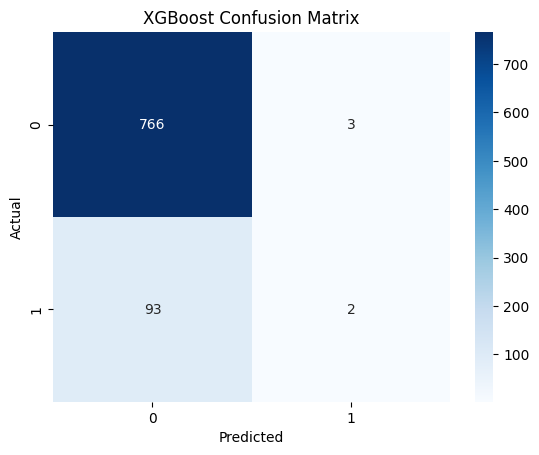

              precision    recall  f1-score   support

           0       0.89      1.00      0.94       769
           1       0.40      0.02      0.04        95

    accuracy                           0.89       864
   macro avg       0.65      0.51      0.49       864
weighted avg       0.84      0.89      0.84       864



In [31]:
# You can convert probabilities to binary predictions using a threshold
threshold = 0.7
xgb_preds = (xgb_probs > threshold).astype(int)

# Confusion matrix
cm = confusion_matrix(y_test, xgb_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Classification Report
print(classification_report(y_test, xgb_preds))


## 9. Feature Importance (XGBoost)

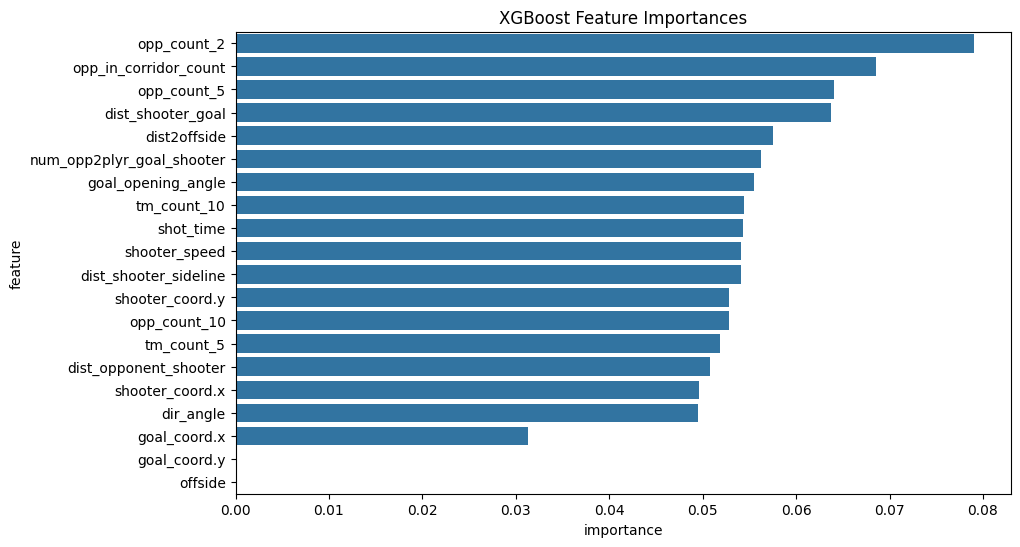

In [146]:
importances = xgb_model.feature_importances_
feature_importance_df = pd.DataFrame({'feature': feature_cols, 'importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='importance', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance_df)
plt.title("XGBoost Feature Importances")
plt.show()


# Hyperparamter Tuning Logitics Regression

In [14]:
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


# Set up the pipeline with a scaler and logistic regression
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000))
])

# Define the parameter grid
param_grid = {
    'logreg__C': np.logspace(-4, 4, 20),  # Range of values for C
    'logreg__penalty': ['l1', 'l2']  # L1 and L2 regularization
}

# Set up the grid search with cross-validation
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='roc_auc')

# Fit grid search
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score: {:.2f}".format(grid_search.best_score_))

# Predict probabilities using the best model found
logreg_probs = grid_search.predict_proba(X_test)[:, 1]

Best parameters: {'logreg__C': 0.23357214690901212, 'logreg__penalty': 'l2'}
Best cross-validation score: 0.64


/Users/svasquez/driblab/dl-vision/.venv/lib/python3.8/site-packages/sklearn/model_selection/_validation.py:378: FitFailedWarning: 
100 fits failed out of a total of 200.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
100 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/svasquez/driblab/dl-vision/.venv/lib/python3.8/site-packages/sklearn/model_selection/_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/svasquez/driblab/dl-vision/.venv/lib/python3.8/site-packages/sklearn/pipeline.py", line 382, in fit
    self._final_estimator.fit(Xt, y, **fit_params_last_step)
  File "/Users/svasquez/driblab/dl-vision/.venv/lib/python3.8/site-packages/sklea

In [15]:
from sklearn.metrics import roc_auc_score, brier_score_loss

# Already given: Prediction probabilities for the test set
test_probs = grid_search.predict_proba(X_test)[:, 1]

# Calculate AUC on the test set
test_auc = roc_auc_score(y_test, test_probs)
print("Test AUC: {:.2f}".format(test_auc))

# Calculate Brier score loss
test_brier_score = brier_score_loss(y_test, test_probs)
print("Test Brier Score Loss: {:.4f}".format(test_brier_score))

Test AUC: 0.66
Test Brier Score Loss: 0.0859


# Save model

In [149]:
import joblib

# Save the logistic regression model
model_path = 'stats/xG/models/logreg_model.joblib'
joblib.dump(grid_search.best_estimator_, model_path)

# Save feature names for later use
feature_names_path = 'stats/xG/models/logreg_feature_names.joblib' 
joblib.dump(X_train.columns.tolist(), feature_names_path)


print(f"Model saved to {model_path}")
print(f"Feature names saved to {feature_names_path}")


Model saved to stats/xG/models/logreg_model.joblib
Feature names saved to stats/xG/models/logreg_feature_names.joblib


In [23]:


# Save the model
model_path = 'stats/xG/models/xg_model.joblib'
joblib.dump(xgb_model, model_path)


print(f"Model saved to {model_path}")
print(f"Feature names saved to models/feature_names.joblib")


Model saved to stats/xG/models/xg_model.joblib
Feature names saved to models/feature_names.joblib
